# Tamweel Lite: Final Project Notebook

An end-to-end tabular machine-learning project that ranks synthetic loan applications by 90-day default risk, compares single models with ensembles using leakage-safe forward validation, freezes a cost- and capacity-aware review policy, calibrates and explains the final model, and exports reproducible challenge predictions.

**What this notebook does.** It is the final overview of the project. It sets up the workspace, redraws every figure from the saved outputs of the five gates, and finishes with the final result and integrity checks on the submission file. It does not retrain any model, so **Runtime > Run all** finishes in about a minute on the free CPU.

**Data:** synthetic (`tamweel-lite-1.0`). For training use only, not for real financing decisions.

| Part | Content |
|---|---|
| 1 | Setup |
| 2 | Data and project roles |
| 3 | Gate 1: baseline boosting models |
| 4 | Gate 2: honest validation |
| 5 | Gate 3: cost-sensitive decision |
| 6 | Gate 4: explanation and calibration |
| 7 | Gate 5: final model |
| 8 | Final result |
| 9 | Interpretation and limitations |

The full write-up is in `README.md` and `docs/TECHNICAL_REPORT.md`. The individual lab notebooks that produced these outputs are in `notebooks/`.

## Part 1: Setup

The next cell finds the project folder. When it is opened in a fresh Colab session, it downloads the public repository first. It needs only `numpy`, `pandas`, `matplotlib` and `scikit-learn`, which Colab already provides.

In [1]:
import os, sys, json, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

REPO_URL = "https://github.com/Jumanah-A/SDA-DSC-211.git"

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/data_contract.json").is_file() and (p / "artifacts").is_dir():
            return p
    return None

ROOT = find_root()
if ROOT is None:                                   # fresh Colab session: get the repository
    target = Path("/content/SDA-DSC-211")
    if not target.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(target)], check=True)
    ROOT = target
os.chdir(ROOT)

def evidence(gate_folder, name):
    """Outputs of the earlier gates live in evidence/<gate folder>/."""
    return ROOT / "evidence" / gate_folder / name

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

BLUE, ORANGE, GREEN, GOLD, GREY = "#286e98", "#b85a1a", "#1b8a6b", "#c49a3a", "#777777"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 211
print("Project folder:", ROOT.name)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", mpl.__version__)

Project folder: SDA-DSC-211
numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0


## Part 2: Data and project roles

The target is `default_within_90d`, a simulated default event within 90 days of an application. The model uses 22 features known at application time. Identifiers, dates and the target are never inputs, and the leaky field `days_past_due_60` is removed.

The training history is split into three roles. July to September 2024 is reserved for calibration only, and customers who appear there (or whose label was not yet mature) are kept out of fitting and selection.

In [2]:
contract = read_json("data/data_contract.json")
train = pd.read_csv("data/tamweel_train.csv")
challenge = pd.read_csv("data/tamweel_challenge.csv")
roles = pd.read_csv("artifacts/day5_roles.csv")
target = "default_within_90d"

print(f"Training file : {len(train):,} rows | default rate {train[target].mean():.1%} | "
      f"{train.application_date.min()} to {train.application_date.max()}")
print(f"Challenge file: {len(challenge):,} unlabeled requests")
print(f"Model inputs  : {len(contract['features'])} features")
print("  " + ", ".join(f["name"] for f in contract["features"]))

summary = (roles.merge(train[["application_id", target]], on="application_id", how="left")
           .groupby("role").agg(rows=("application_id", "size"), customers=("customer_id", "nunique"),
                                positives=(target, "sum"), first=("application_date", "min"),
                                last=("application_date", "max")))
summary.index = ["calibration only", "excluded (gap, customer overlap or label not mature)", "fit and selection pool"]
display(summary)

Training file : 10,000 rows | default rate 7.9% | 2022-01-01 to 2024-12-31
Challenge file: 2,500 unlabeled requests
Model inputs  : 22 features
  age, income_sar, loan_amount_sar, tenor_months, bureau_score, dti, months_employed, recent_inquiries, prior_defaults, existing_obligations_sar, savings_balance_sar, salary_transfer, credit_history_months, utilization_ratio, num_open_accounts, residence_years, region_central, region_western, region_eastern, employment_government, employment_private, employment_self_employed


,rows,customers,positives,first,last
calibration only,836,788,78,2024-07-01,2024-09-30
"excluded (gap, customer overlap or label not mature)",2588,1949,174,2022-01-03,2024-12-31
fit and selection pool,6576,3931,537,2022-01-01,2024-04-01


## Part 3: Gate 1, baseline boosting models

Logistic Regression, XGBoost and LightGBM are compared first. The tree counts of the two boosting models are chosen on inner rows only, so the comparison does not reuse the rows used for fitting.

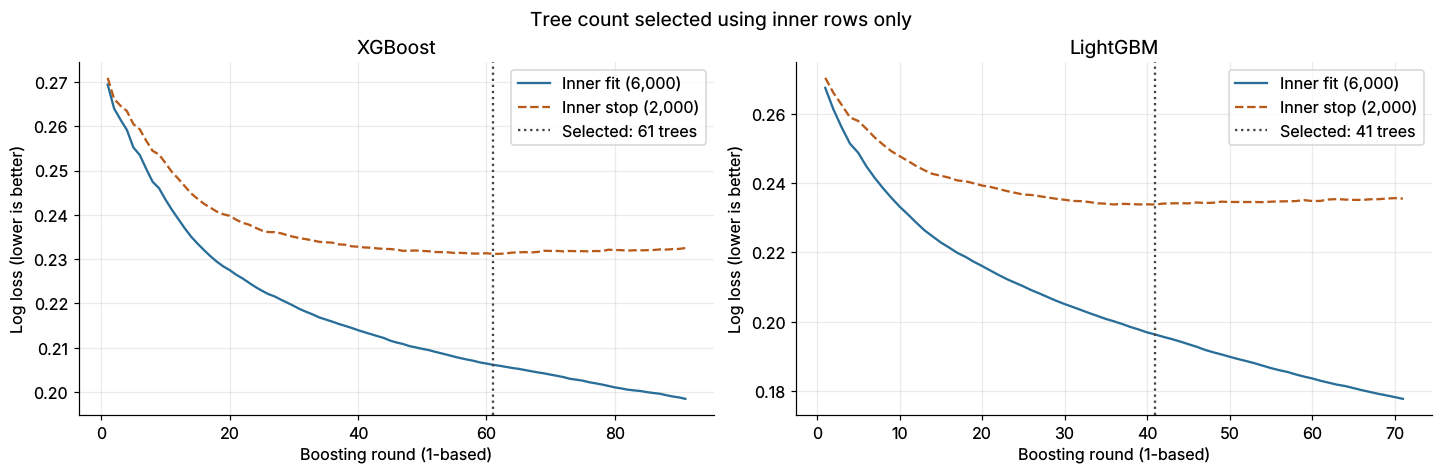

In [3]:
run_g1 = read_json(evidence("day1", "day1_run.json"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
for ax, name in zip(axes, ["XGBoost", "LightGBM"]):
    sel = run_g1["selections"][name]
    fit, stop = sel["curves"]["fit"], sel["curves"]["stop"]
    rounds = np.arange(1, len(fit) + 1)
    ax.plot(rounds, fit, color=BLUE, label="Inner fit (6,000)")
    ax.plot(rounds, stop, "--", color=ORANGE, label="Inner stop (2,000)")
    ax.axvline(sel["selected_trees"], color="#444", ls=":", label=f"Selected: {sel['selected_trees']} trees")
    ax.set(title=name, xlabel="Boosting round (1-based)", ylabel="Log loss (lower is better)")
    ax.legend()
fig.suptitle("Tree count selected using inner rows only")
plt.show()

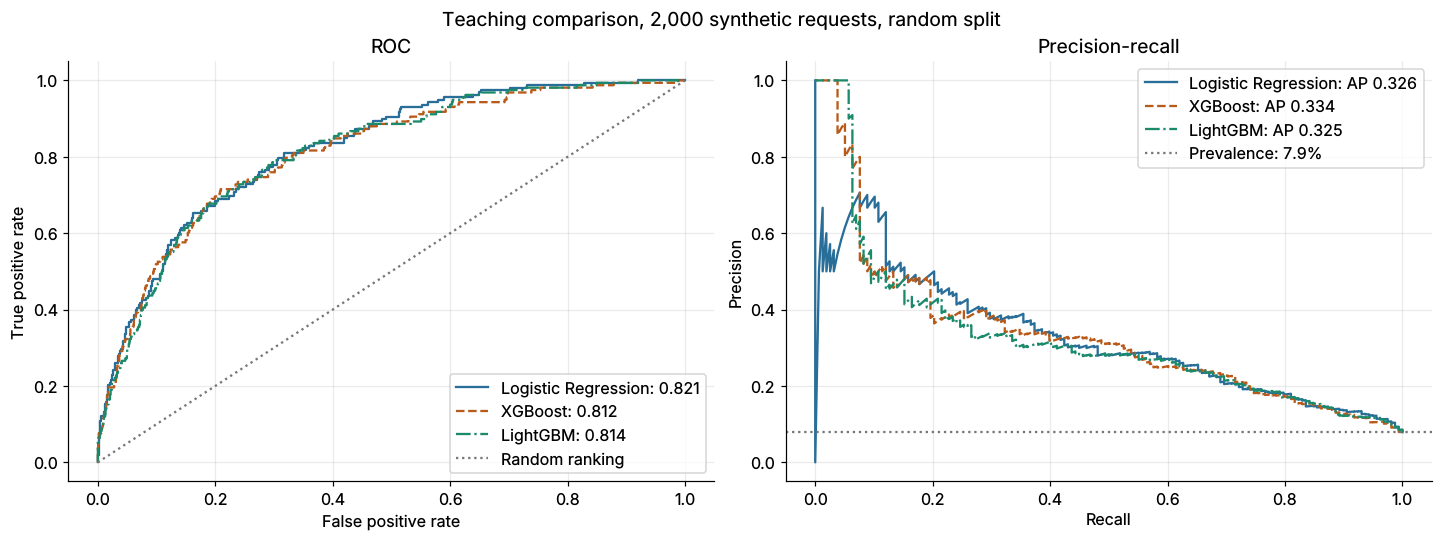

,roc_auc,average_precision
model,,
Logistic Regression,0.8213,0.3258
XGBoost,0.8124,0.3338
LightGBM,0.8138,0.3248


In [4]:
pred_g1 = pd.read_csv(evidence("day1", "day1_comparison_predictions.csv"))
y1 = pred_g1[target].values
style = {"Logistic Regression": (BLUE, "-"), "XGBoost": (ORANGE, "--"), "LightGBM": (GREEN, "-.")}
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
rows = []
for model, (color, ls) in style.items():
    fpr, tpr, _ = roc_curve(y1, pred_g1[model]); auc = roc_auc_score(y1, pred_g1[model])
    prec, rec, _ = precision_recall_curve(y1, pred_g1[model]); ap = average_precision_score(y1, pred_g1[model])
    ax_roc.plot(fpr, tpr, color=color, ls=ls, label=f"{model}: {auc:.3f}")
    ax_pr.plot(rec, prec, color=color, ls=ls, label=f"{model}: AP {ap:.3f}")
    rows.append({"model": model, "roc_auc": round(auc, 4), "average_precision": round(ap, 4)})
ax_roc.plot([0, 1], [0, 1], ":", color=GREY, label="Random ranking")
ax_pr.axhline(y1.mean(), ls=":", color=GREY, label=f"Prevalence: {y1.mean():.1%}")
ax_roc.set(title="ROC", xlabel="False positive rate", ylabel="True positive rate"); ax_roc.legend(loc="lower right")
ax_pr.set(title="Precision-recall", xlabel="Recall", ylabel="Precision"); ax_pr.legend()
fig.suptitle(f"Teaching comparison, {len(y1):,} synthetic requests, random split")
plt.show()
display(pd.DataFrame(rows).set_index("model"))

**Reading Gate 1.** The three models are almost indistinguishable on ROC (AUC about 0.81 to 0.82). Because defaults are rare (7.9%), average precision is the more informative metric, and XGBoost scored highest (0.334). The gaps are small, and this was a random split, so it is a first look and not an honest test.

## Part 4: Gate 2, honest validation

Validation is forward in time: training uses only applications whose 90-day outcome had already matured, and validation customers are removed from training. A leaky control is included to show how much leakage can inflate a score.

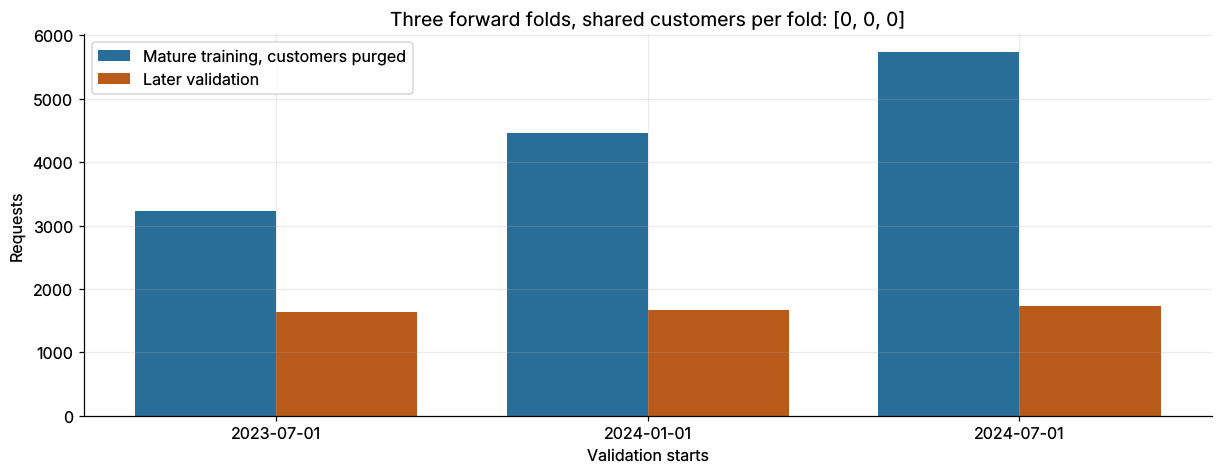

,fold,validation_start,train_rows,validation_rows,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers
0,1,2023-07-01,3223,1632,826,912,0
1,2,2024-01-01,4460,1674,785,1348,0
2,3,2024-07-01,5731,1733,861,1675,0


In [5]:
folds = pd.read_csv(evidence("day2", "fold_audit.csv"))
x = np.arange(len(folds)); w = .38
fig, ax = plt.subplots(figsize=(11, 4.2), layout="constrained")
ax.bar(x - w/2, folds.train_rows, w, color=BLUE, label="Mature training, customers purged")
ax.bar(x + w/2, folds.validation_rows, w, color=ORANGE, label="Later validation")
ax.set_xticks(x, folds.validation_start); ax.set(xlabel="Validation starts", ylabel="Requests")
ax.set_title(f"Three forward folds, shared customers per fold: {folds.shared_customers.tolist()}")
ax.legend(); plt.show()
display(folds[["fold", "validation_start", "train_rows", "validation_rows", "immature_past_rows_removed",
               "customer_overlap_rows_removed", "shared_customers"]])

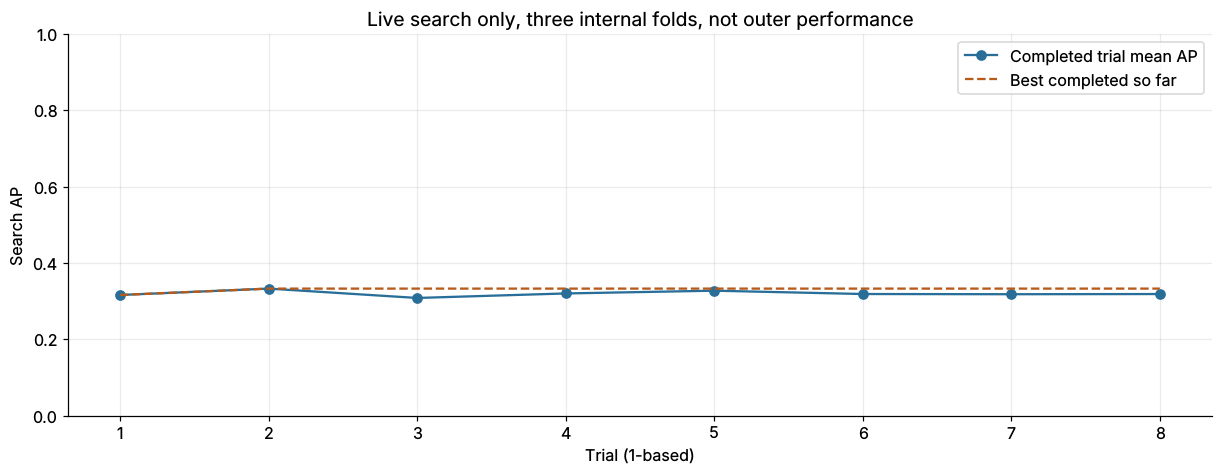

In [6]:
trials = pd.read_csv(evidence("day2", "optuna_results.csv"))
done = trials[trials.state == "COMPLETE"].copy()
done["best_so_far"] = done.mean_ap.cummax()
fig, ax = plt.subplots(figsize=(11, 4.2), layout="constrained")
ax.plot(done.trial + 1, done.mean_ap, "o-", color=BLUE, label="Completed trial mean AP")
ax.plot(done.trial + 1, done.best_so_far, "--", color=ORANGE, label="Best completed so far")
ax.set(ylim=(0, 1), xlabel="Trial (1-based)", ylabel="Search AP",
       title="Live search only, three internal folds, not outer performance")
ax.legend(); plt.show()

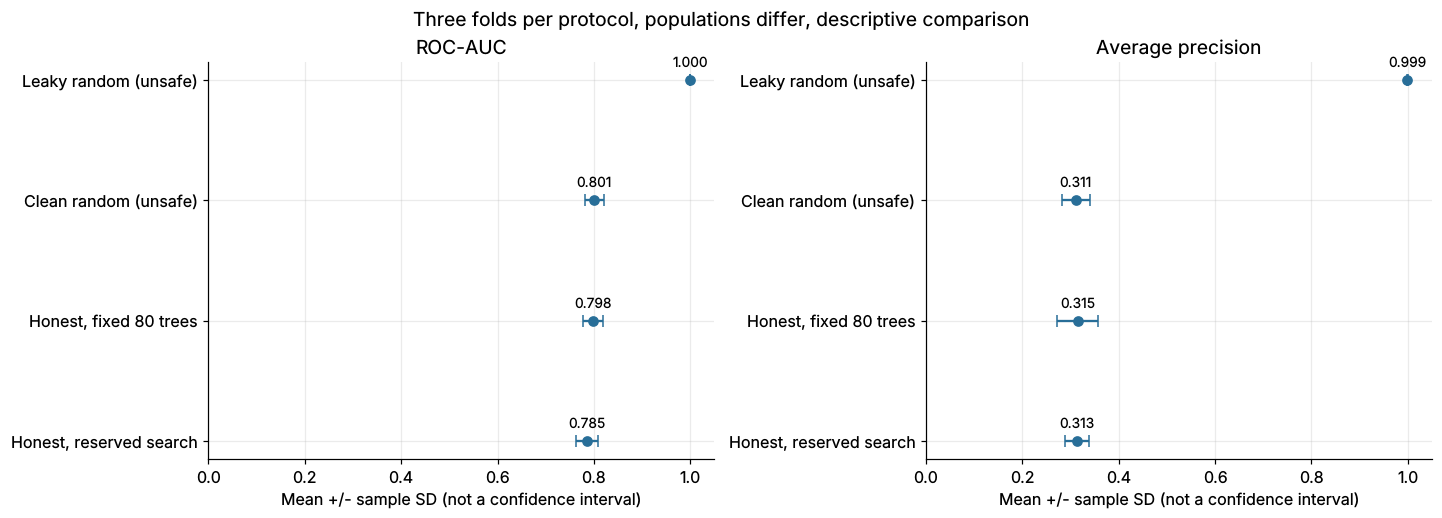

In [7]:
val = pd.read_csv(evidence("day2", "validation_summary.csv")).set_index("scheme")
names = {"leaky_random_control": "Leaky random (unsafe)", "clean_random_control": "Clean random (unsafe)",
         "clean_time_group_fixed": "Honest, fixed 80 trees", "clean_time_group_tuned": "Honest, reserved search"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
for ax, (col, title) in zip(axes, [("roc_auc", "ROC-AUC"), ("ap", "Average precision")]):
    for i, key in enumerate(names):
        m, s = val.loc[key, f"{col}_mean"], val.loc[key, f"{col}_sd"]
        ax.errorbar(m, i, xerr=s, fmt="o", color=BLUE, capsize=4)
        ax.annotate(f"{m:.3f}", (m, i), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
    ax.set_yticks(range(len(names)), names.values()); ax.invert_yaxis(); ax.set_xlim(0, 1.05)
    ax.set(title=title, xlabel="Mean +/- sample SD (not a confidence interval)")
fig.suptitle("Three folds per protocol, populations differ, descriptive comparison")
plt.show()

**Reading Gate 2.** Training grows with each later fold, and no customer is shared between training and validation. The hyperparameter search barely moved (AP about 0.31 to 0.33), so tuning added little. The leaky control scored AP 0.999, which is far too good to be real. Once future information is removed and time and customers are respected, AP is about 0.31 for every honest protocol. That gap is what leakage looks like.

## Part 5: Gate 3, cost-sensitive decision

A missed default costs 10 units and a false alarm costs 1, and only 12% of requests can be reviewed in each period. The threshold is therefore chosen by loss under a capacity ceiling instead of defaulting to 0.5.

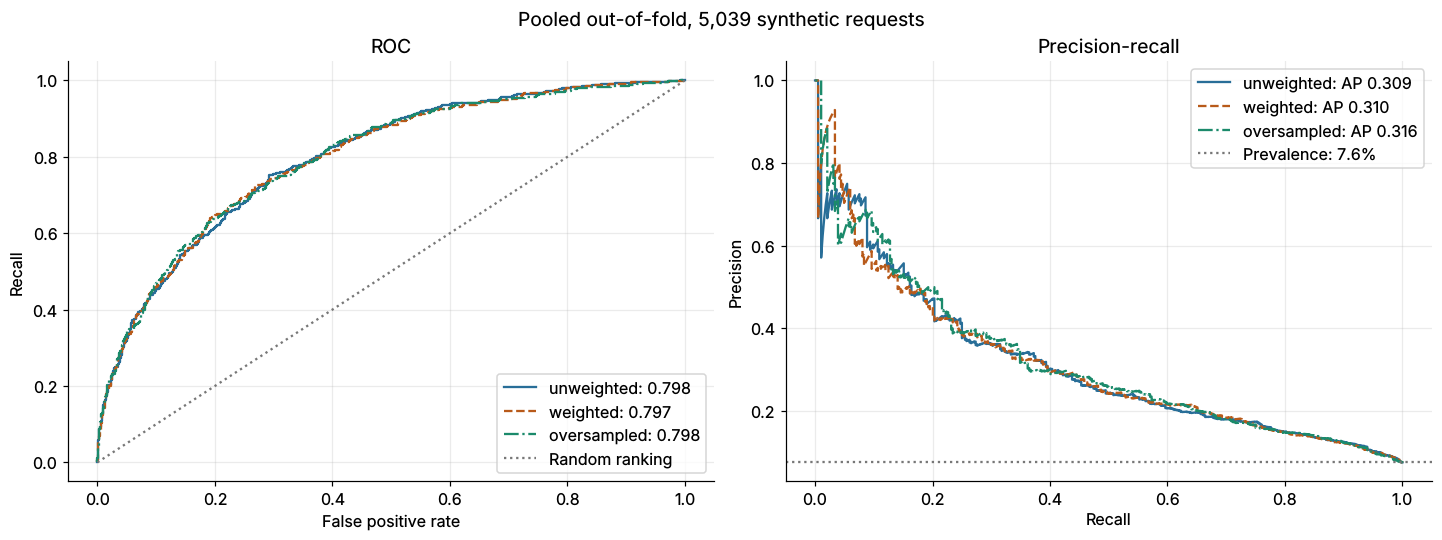

,requests,roc_auc,average_precision
strategy,,,
unweighted,5039,0.7979,0.3091
weighted,5039,0.7969,0.3100
oversampled,5039,0.7979,0.3159


In [8]:
oof_g3 = pd.read_csv(evidence("day3", "day3_oof_predictions.csv"))
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
rows = []
for strategy, (color, ls) in zip(["unweighted", "weighted", "oversampled"], [(BLUE, "-"), (ORANGE, "--"), (GREEN, "-.")]):
    g = oof_g3[oof_g3.strategy == strategy]
    fpr, tpr, _ = roc_curve(g[target], g.probability); auc = roc_auc_score(g[target], g.probability)
    prec, rec, _ = precision_recall_curve(g[target], g.probability); ap = average_precision_score(g[target], g.probability)
    ax_roc.plot(fpr, tpr, color=color, ls=ls, label=f"{strategy}: {auc:.3f}")
    ax_pr.plot(rec, prec, color=color, ls=ls, label=f"{strategy}: AP {ap:.3f}")
    rows.append({"strategy": strategy, "requests": len(g), "roc_auc": round(auc, 4), "average_precision": round(ap, 4)})
base_rate = oof_g3.groupby("strategy")[target].mean().iloc[0]
ax_roc.plot([0, 1], [0, 1], ":", color=GREY, label="Random ranking")
ax_pr.axhline(base_rate, ls=":", color=GREY, label=f"Prevalence: {base_rate:.1%}")
ax_roc.set(title="ROC", xlabel="False positive rate", ylabel="Recall"); ax_roc.legend(loc="lower right")
ax_pr.set(title="Precision-recall", xlabel="Recall", ylabel="Precision"); ax_pr.legend()
fig.suptitle(f"Pooled out-of-fold, {rows[0]['requests']:,} synthetic requests")
plt.show()
display(pd.DataFrame(rows).set_index("strategy"))

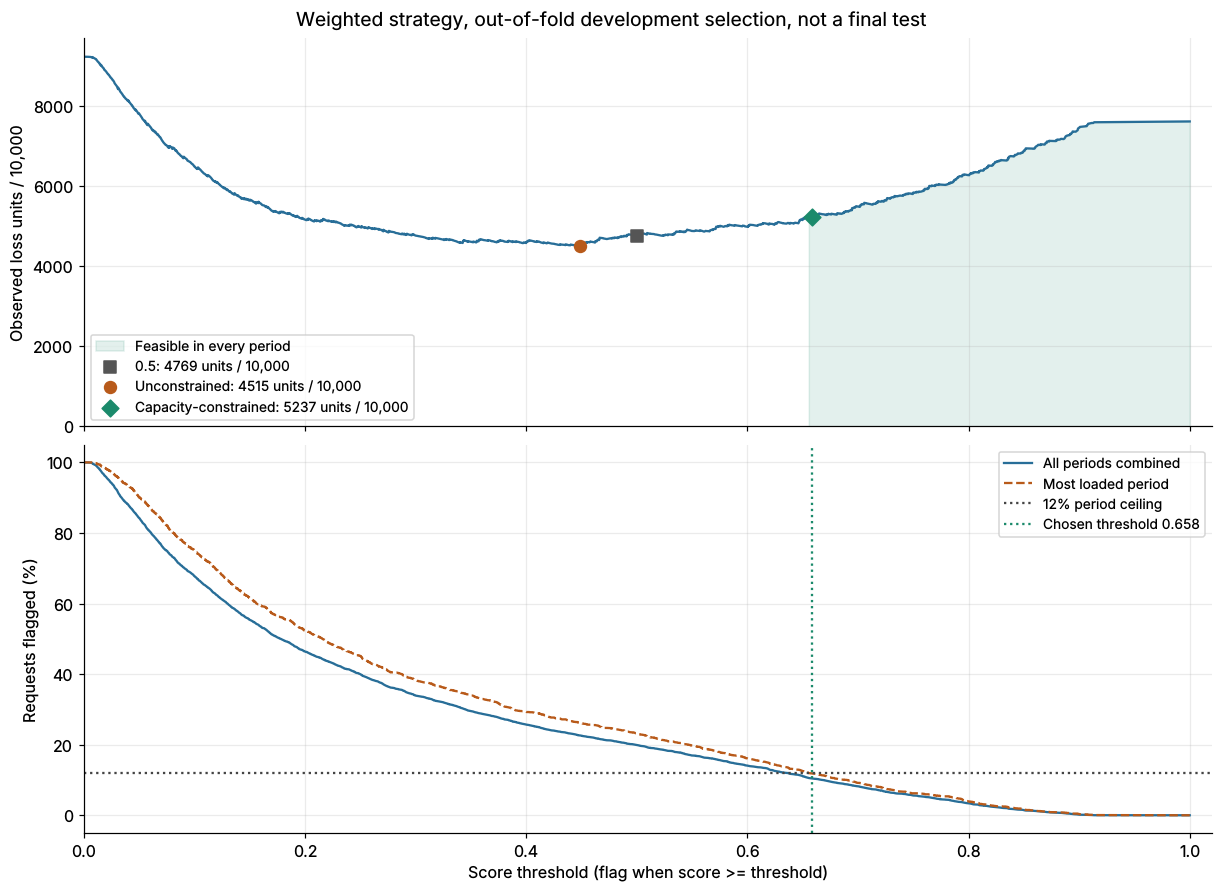

In [9]:
sweep_g3 = pd.read_csv(evidence("day3", "threshold_sweep.csv"))
tm = read_json(evidence("day3", "threshold_metrics.json"))
chosen_g3 = tm["chosen"]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, layout="constrained")
top.plot(sweep_g3.threshold, sweep_g3.loss_units_per_10000, color=BLUE)
feasible = sweep_g3[sweep_g3.capacity_feasible]
top.fill_between(feasible.threshold, 0, feasible.loss_units_per_10000, color=GREEN, alpha=.12, label="Feasible in every period")
for key, label, marker, color in [("default_0_5", "0.5", "s", "#555"), ("unconstrained", "Unconstrained", "o", ORANGE),
                                  ("chosen", "Capacity-constrained", "D", GREEN)]:
    row = tm[key]
    top.scatter(row["threshold"], row["loss_units_per_10000"], marker=marker, s=60, color=color, zorder=5,
                label=f"{label}: {row['loss_units_per_10000']:.0f} units / 10,000")
top.set(ylabel="Observed loss units / 10,000", ylim=(0, None)); top.legend(loc="lower left", fontsize=9)
bottom.plot(sweep_g3.threshold, sweep_g3.flag_fraction * 100, color=BLUE, label="All periods combined")
bottom.plot(sweep_g3.threshold, sweep_g3.max_period_flag_fraction * 100, "--", color=ORANGE, label="Most loaded period")
bottom.axhline(12, ls=":", color="#444", label="12% period ceiling")
bottom.axvline(chosen_g3["threshold"], ls=":", color=GREEN, label=f"Chosen threshold {chosen_g3['threshold']:.3f}")
bottom.set(xlabel="Score threshold (flag when score >= threshold)", ylabel="Requests flagged (%)", xlim=(0, 1.02)); bottom.legend(fontsize=9)
fig.suptitle("Weighted strategy, out-of-fold development selection, not a final test")
plt.show()

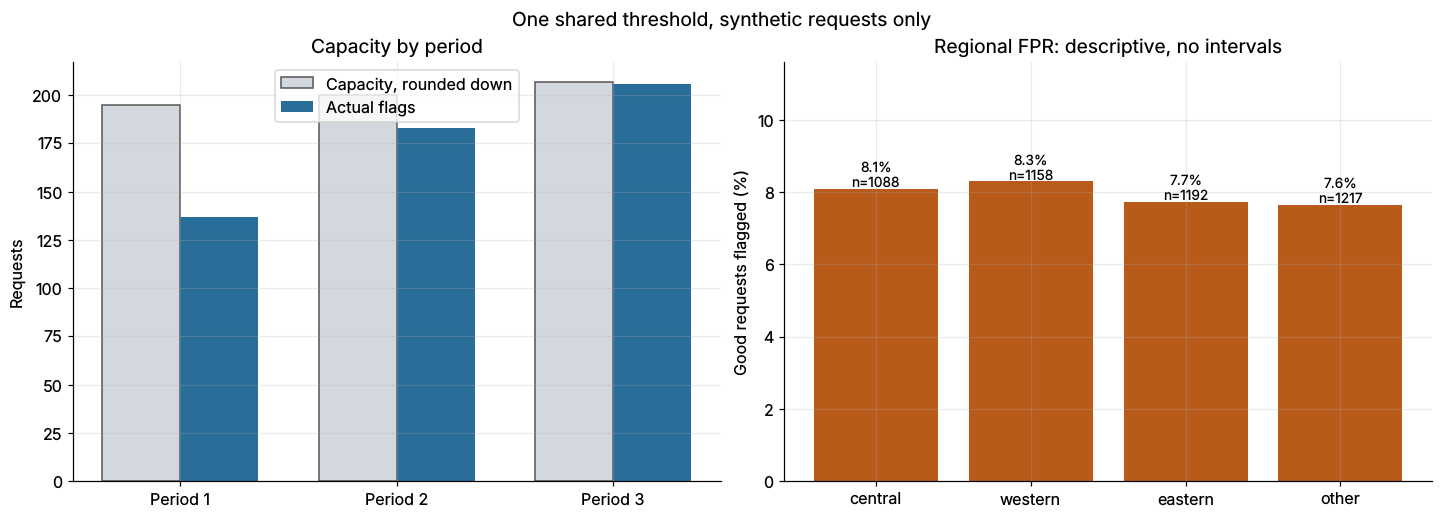

,fold,rows,capacity,flagged,flag_fraction,within_capacity
0,1,1632,195,137,0.083946,True
1,2,1674,200,183,0.109319,True
2,3,1733,207,206,0.118869,True


In [10]:
cap_g3 = pd.read_csv(evidence("day3", "day3_period_capacity.csv"))
reg_g3 = pd.read_csv(evidence("day3", "day3_region_audit.csv"))
fig, (ax_cap, ax_reg) = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
x = np.arange(len(cap_g3)); w = .36
ax_cap.bar(x - w/2, cap_g3.capacity, w, color="#d3d8de", edgecolor="#555", label="Capacity, rounded down")
ax_cap.bar(x + w/2, cap_g3.flagged, w, color=BLUE, label="Actual flags")
ax_cap.set_xticks(x, [f"Period {i}" for i in cap_g3.fold]); ax_cap.set(title="Capacity by period", ylabel="Requests"); ax_cap.legend()
ax_reg.bar(reg_g3.region, reg_g3.false_positive_rate * 100, color=ORANGE)
for i, r in reg_g3.iterrows():
    ax_reg.text(i, r.false_positive_rate * 100, f"{r.false_positive_rate:.1%}\nn={r.negatives}", ha="center", va="bottom", fontsize=9)
ax_reg.set(title="Regional FPR: descriptive, no intervals", ylabel="Good requests flagged (%)", ylim=(0, reg_g3.false_positive_rate.max() * 100 * 1.4))
fig.suptitle("One shared threshold, synthetic requests only")
plt.show()
display(cap_g3[["fold", "rows", "capacity", "flagged", "flag_fraction", "within_capacity"]])

**Reading Gate 3.** Handling class imbalance by weighting or oversampling barely changes how well requests are ranked; the real lever is the threshold. With no limit the lowest loss is at a threshold near 0.45. The default 0.5 would flag about 20% of requests, which is over the 12% ceiling. The chosen threshold (0.658) is the lowest-loss one that keeps every period within capacity. It costs more loss, which is the price of respecting review capacity. The regional gap is small and is a descriptive diagnostic, not a fairness certification.

## Part 6: Gate 4, explanation and calibration

The Gate 4 model is explained with permutation importance and SHAP, then its probabilities are calibrated with a sigmoid mapping. These explanations belong to the Gate 4 LightGBM model, not to the final Logistic model.

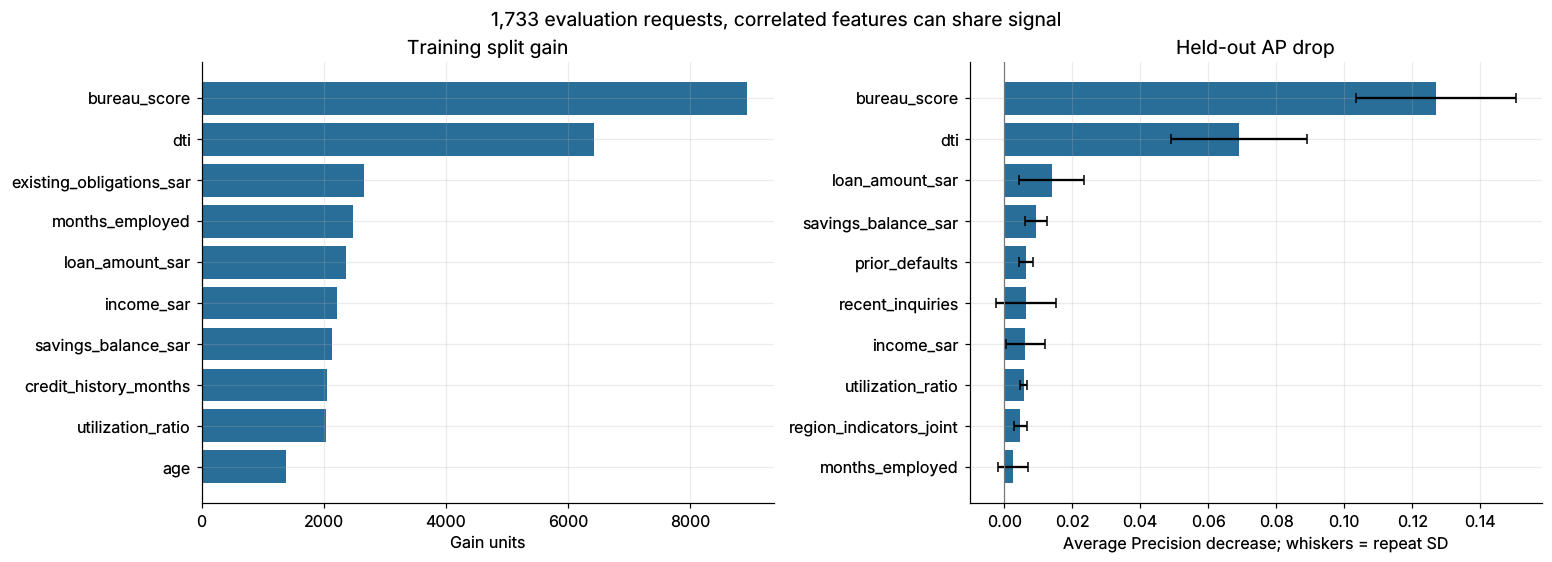

In [11]:
perm = pd.read_csv(evidence("day4", "permutation_importance.csv"))
by_gain = perm.sort_values("training_gain", ascending=False).head(10).iloc[::-1]
by_drop = perm.sort_values("mean_ap_drop", ascending=False).head(10).iloc[::-1]
fig, (ax_gain, ax_drop) = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
ax_gain.barh(by_gain.feature_group, by_gain.training_gain, color=BLUE); ax_gain.set(title="Training split gain", xlabel="Gain units")
ax_drop.barh(by_drop.feature_group, by_drop.mean_ap_drop, xerr=by_drop.repeat_sd, color=BLUE, error_kw={"capsize": 3})
ax_drop.axvline(0, color=GREY, lw=.8)
ax_drop.set(title="Held-out AP drop", xlabel="Average Precision decrease; whiskers = repeat SD")
fig.suptitle(f"{int(perm.rows.iloc[0]):,} evaluation requests, correlated features can share signal")
plt.show()

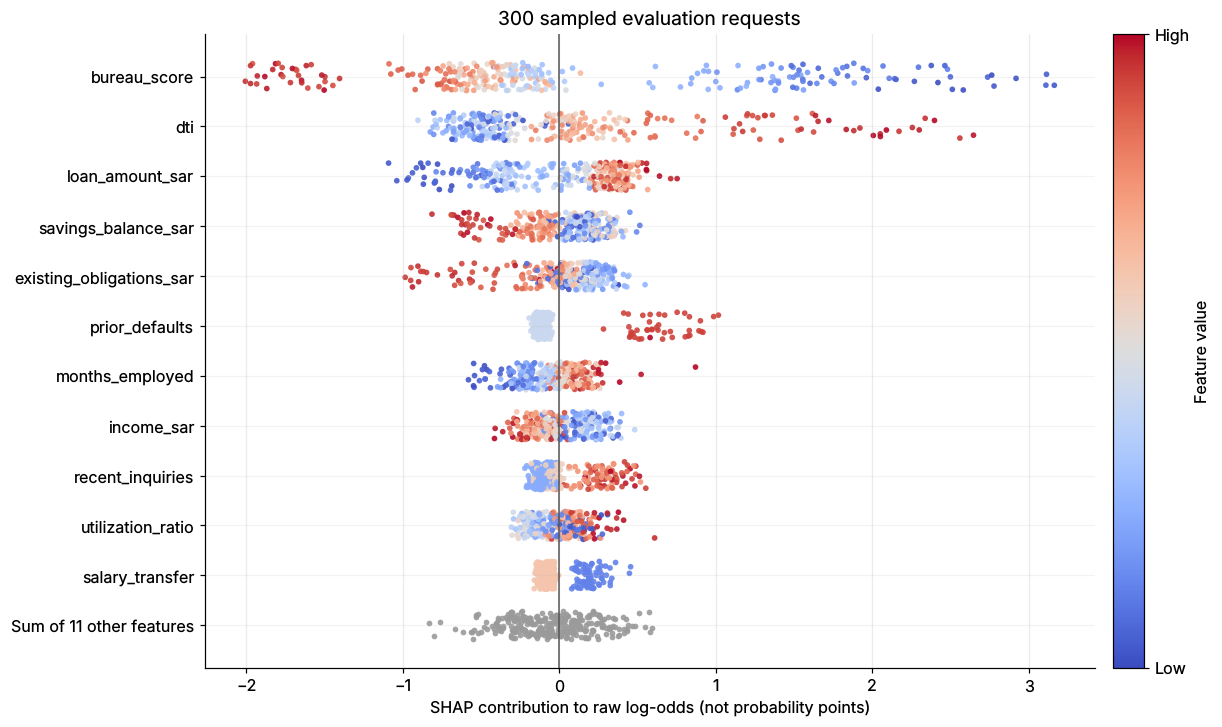

In [12]:
npz = np.load(evidence("day4", "shap_values_sample.npz"), allow_pickle=True)
shap_values, shap_data = npz["values"], npz["data"]
feature_names = [str(n) for n in npz["feature_names"]]
order = np.argsort(-np.abs(shap_values).mean(axis=0))
top_idx, rest_idx = order[:11], order[11:]
rows = [(feature_names[i], shap_values[:, i], shap_data[:, i]) for i in top_idx]
rows.append((f"Sum of {len(rest_idx)} other features", shap_values[:, rest_idx].sum(axis=1), None))
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(11, 6.5), layout="constrained")
cmap = plt.cm.coolwarm
for k, (name, v, d) in enumerate(rows):
    color = "#9a9a9a" if d is None else cmap(pd.Series(d).rank(pct=True).values)
    ax.scatter(v, k + rng.uniform(-.28, .28, len(v)), c=color, s=14, alpha=.9, linewidths=0)
ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis()
ax.axvline(0, color="#555", lw=1); ax.grid(axis="y", alpha=.15)
ax.set(xlabel="SHAP contribution to raw log-odds (not probability points)", title=f"{len(shap_values)} sampled evaluation requests")
cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 1), cmap=cmap), ax=ax, ticks=[0, 1], pad=.02)
cbar.ax.set_yticklabels(["Low", "High"]); cbar.set_label("Feature value")
plt.show()

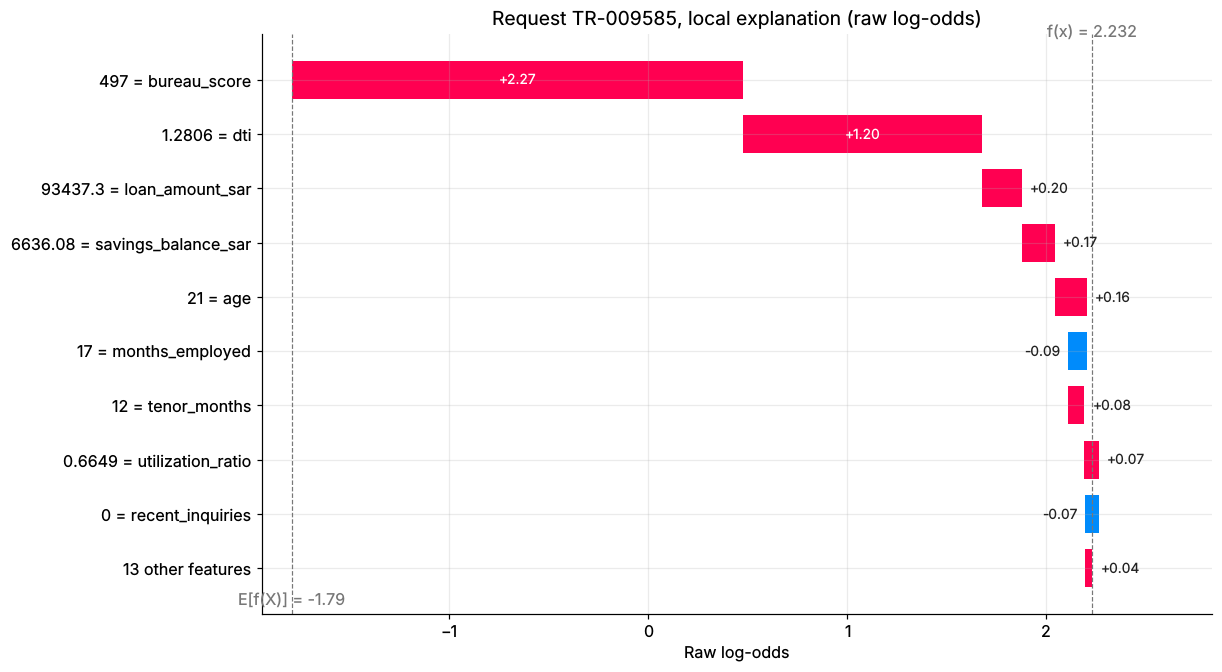

additivity check: base + sum(SHAP) - raw margin = -4.44e-16


In [13]:
i = int(np.argmax(npz["raw_margin"]))                     # highest-scoring request in the sample
base, margin, app_id = float(npz["base_values"][i]), float(npz["raw_margin"][i]), str(npz["application_ids"][i])
contrib = shap_values[i]
top9 = np.argsort(-np.abs(contrib))[:9]
items = [(f"{shap_data[i, j]:g} = {feature_names[j]}", float(contrib[j])) for j in top9]
items.append((f"{len(contrib) - 9} other features", float(np.delete(contrib, top9).sum())))
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
left = base
for k, (label, c) in enumerate(items):
    ax.barh(k, c, left=left, color="#ff0051" if c > 0 else "#008bfb", height=.7)
    ax.text(left + c / 2 if abs(c) > .25 else left + c + (.04 if c > 0 else -.04), k, f"{c:+.2f}",
            ha="center" if abs(c) > .25 else ("left" if c > 0 else "right"), va="center",
            color="white" if abs(c) > .25 else "#222", fontsize=9)
    left += c
ax.set_yticks(range(len(items)), [t[0] for t in items]); ax.invert_yaxis()
ax.axvline(base, color=GREY, ls="--", lw=.8); ax.axvline(margin, color=GREY, ls="--", lw=.8)
ax.text(base, len(items) - .35, f"E[f(X)] = {base:.2f}", ha="center", color=GREY)
ax.text(margin, -.8, f"f(x) = {margin:.3f}", ha="center", color=GREY)
ax.set(xlabel="Raw log-odds", title=f"Request {app_id}, local explanation (raw log-odds)", xlim=(base - .15, margin + .6))
plt.show()
print(f"additivity check: base + sum(SHAP) - raw margin = {base + contrib.sum() - margin:.2e}")

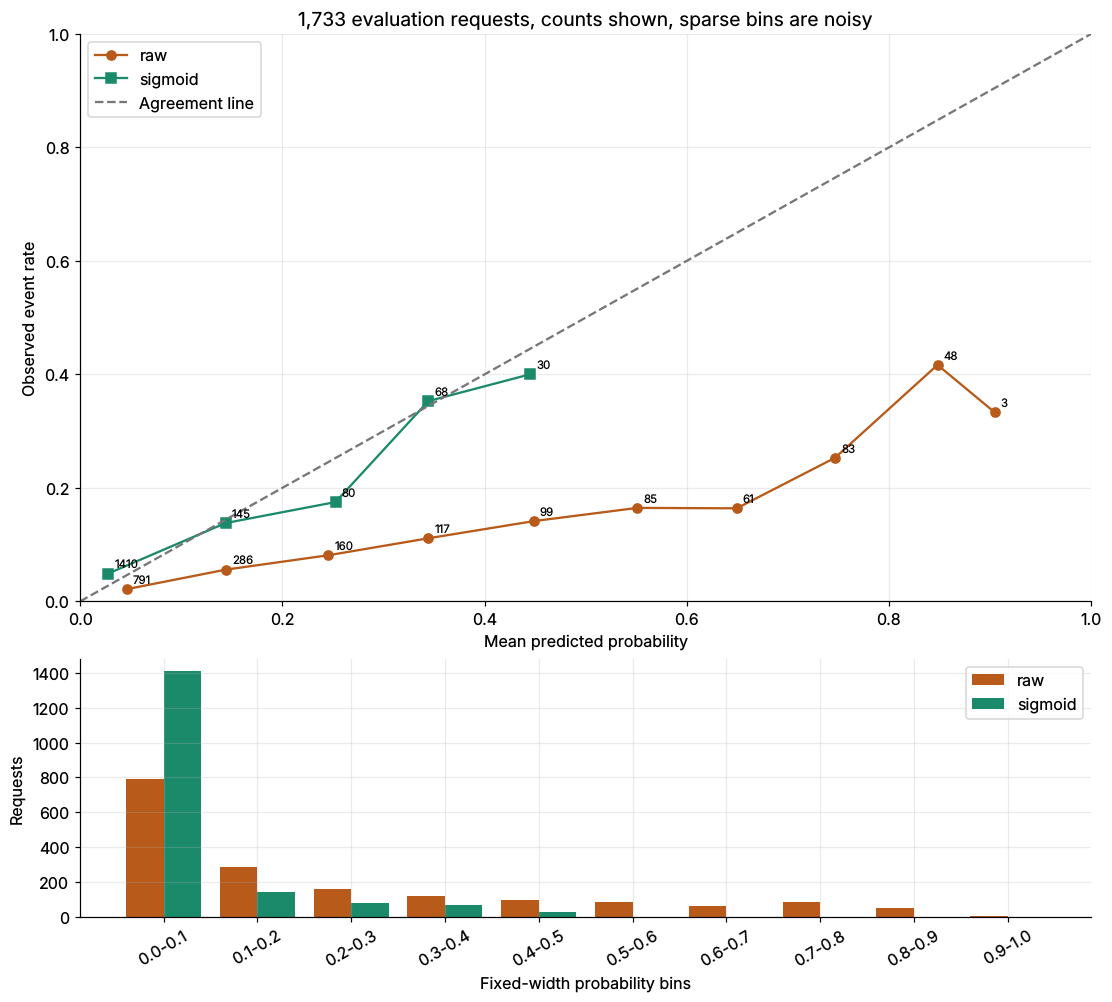

Brier change : -0.0459 | ECE change: -0.1244


In [14]:
rel = pd.read_csv(evidence("day4", "day4_reliability_bins.csv"))
fig, (ax, ax_counts) = plt.subplots(2, 1, figsize=(10, 9), gridspec_kw={"height_ratios": [2.2, 1]}, layout="constrained")
for variant, color, marker in [("raw", ORANGE, "o"), ("sigmoid", GREEN, "s")]:
    t = rel[(rel.variant == variant) & (rel["count"] > 0)]
    ax.plot(t.mean_probability, t.observed_rate, marker + "-", color=color, label=variant)
    for _, r in t.iterrows():
        ax.annotate(str(int(r["count"])), (r.mean_probability, r.observed_rate), xytext=(4, 4), textcoords="offset points", fontsize=7.5)
ax.plot([0, 1], [0, 1], "--", color=GREY, label="Agreement line")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed event rate")
ax.set_title("1,733 evaluation requests, counts shown, sparse bins are noisy"); ax.legend()
w = .4
for k, (variant, color) in enumerate([("raw", ORANGE), ("sigmoid", GREEN)]):
    t = rel[rel.variant == variant].sort_values("bin")
    ax_counts.bar(t.bin + (k - .5) * w, t["count"], w, color=color, label=variant)
ax_counts.set_xticks(range(10), [f"{lo:.1f}-{hi:.1f}" for lo, hi in zip(rel[rel.variant == "raw"].lower, rel[rel.variant == "raw"].upper)], rotation=30)
ax_counts.set(xlabel="Fixed-width probability bins", ylabel="Requests"); ax_counts.legend()
plt.show()
cal = read_json(evidence("day4", "calibration_metrics.json"))
print("Brier change :", round(cal["brier_change"], 4), "| ECE change:", round(cal["ece_change"], 4))

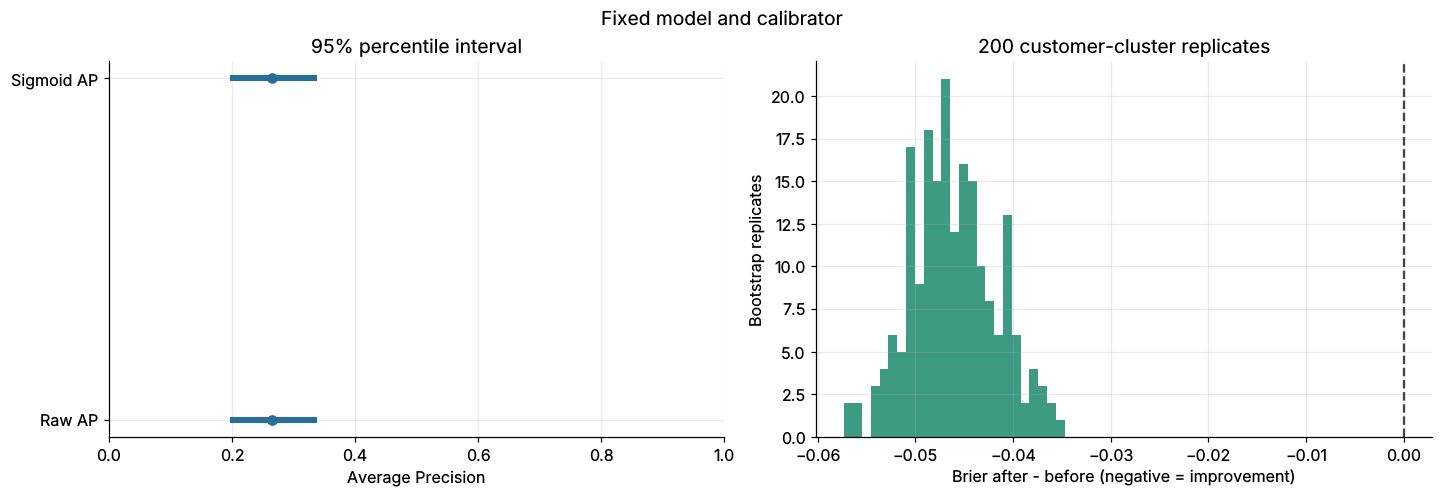

Brier change: all 200 replicates negative = True | range -0.057 to -0.035


In [15]:
boot = pd.read_csv(evidence("day4", "day4_bootstrap.csv"))
fig, (ax_ap, ax_brier) = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
for k, (label, col) in enumerate([("Raw AP", "raw_ap"), ("Sigmoid AP", "calibrated_ap")]):
    lo, mid, hi = boot[col].quantile([.025, .5, .975])
    ax_ap.hlines(k, lo, hi, color=BLUE, lw=4); ax_ap.plot(mid, k, "o", color=BLUE)
ax_ap.set_yticks([0, 1], ["Raw AP", "Sigmoid AP"]); ax_ap.set(xlim=(0, 1), xlabel="Average Precision", title="95% percentile interval")
ax_brier.hist(boot.brier_change, bins=25, color=GREEN, alpha=.85)
ax_brier.axvline(0, color="#444", ls="--")
ax_brier.set(xlabel="Brier after - before (negative = improvement)", ylabel="Bootstrap replicates", title=f"{len(boot)} customer-cluster replicates")
fig.suptitle("Fixed model and calibrator")
plt.show()
print(f"Brier change: all {len(boot)} replicates negative = {bool((boot.brier_change < 0).all())} | range {boot.brier_change.min():.3f} to {boot.brier_change.max():.3f}")

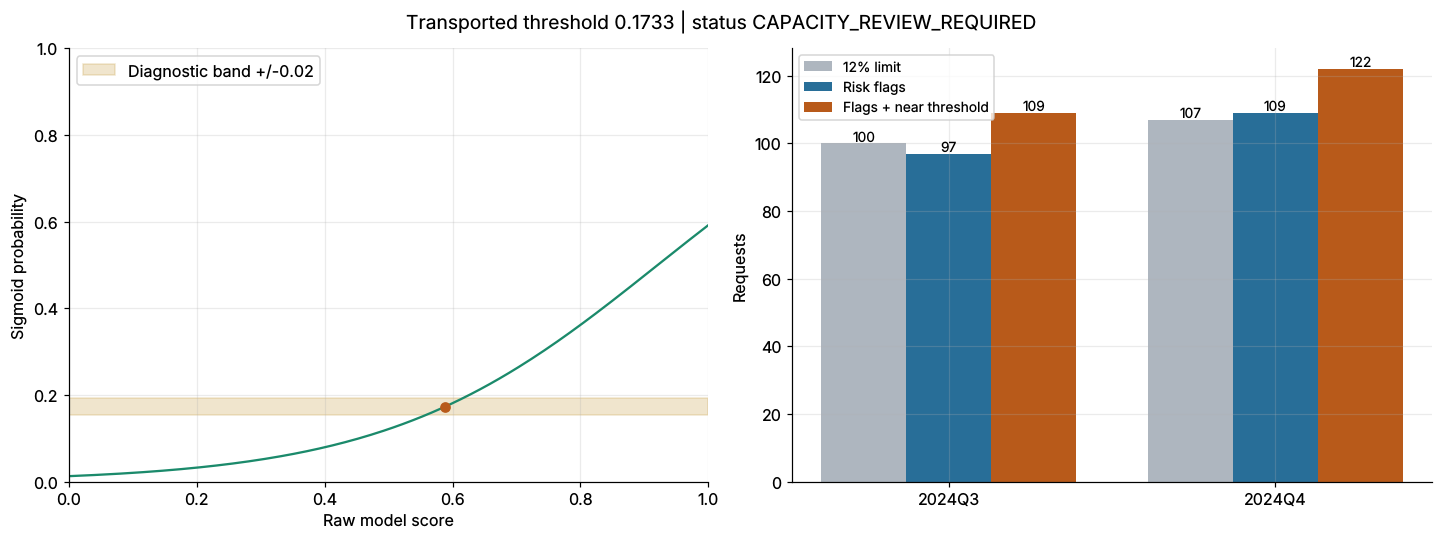

In [16]:
a, b = cal["mapping"]["a"], cal["mapping"]["b"]
raw_t = cal["policy_selection"]["threshold"]; cal_t = cal["calibrated_threshold"]; band = cal["review_band"]
xs = np.linspace(0, 1, 200); ys = 1 / (1 + np.exp(a * xs + b))          # expit(-(a*raw + b))
cap_g4 = pd.read_csv(evidence("day4", "day4_capacity.csv"))
fig, (ax_map, ax_cap) = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
ax_map.axhspan(band["lower"], band["upper"], color=GOLD, alpha=.25, label="Diagnostic band +/-0.02")
ax_map.plot(xs, ys, color=GREEN); ax_map.scatter([raw_t], [cal_t], color=ORANGE, zorder=5)
ax_map.set(xlim=(0, 1), ylim=(0, 1), xlabel="Raw model score", ylabel="Sigmoid probability"); ax_map.legend(loc="upper left")
x = np.arange(len(cap_g4)); w = .26
for k, (col, label, color) in enumerate([("capacity", "12% limit", "#aeb6bf"), ("risk_flags", "Risk flags", BLUE),
                                         ("candidate_review", "Flags + near threshold", ORANGE)]):
    bars = ax_cap.bar(x + (k - 1) * w, cap_g4[col], w, color=color, label=label)
    ax_cap.bar_label(bars, fontsize=9)
ax_cap.set_xticks(x, cap_g4.period); ax_cap.set(ylabel="Requests"); ax_cap.legend(fontsize=9)
fig.suptitle(f"Transported threshold {cal_t:.4f} | status {cal['capacity_status']}")
plt.show()

**Reading Gate 4.** `bureau_score` was the most important feature (shuffling it cost about 0.127 AP), followed by `dti`. SHAP shows how the model used the data: low bureau scores and high debt-to-income push the score up. This describes the model and does not prove causality. For the highest-scoring sample request, bureau score and debt-to-income together account for most of the move from the average to a raw score of 2.23 log-odds. Calibration pulled the over-confident raw scores close to the agreement line (Brier 0.113 to 0.067, ECE 0.147 to 0.022) without changing the ranking, and the improvement held in every bootstrap replicate. On the evaluation quarters the flags plus the near-threshold group exceeded the 12% limit, so the status is `CAPACITY_REVIEW_REQUIRED`, and the threshold was not retuned on evaluation data.

## Part 7: Gate 5, final model

Three single models are compared with equal averaging, weighted averaging and stacking on nested forward out-of-fold predictions. An ensemble is accepted only if its AP gain beats the best single model's fold standard deviation without worsening Brier or ECE beyond fixed tolerances.

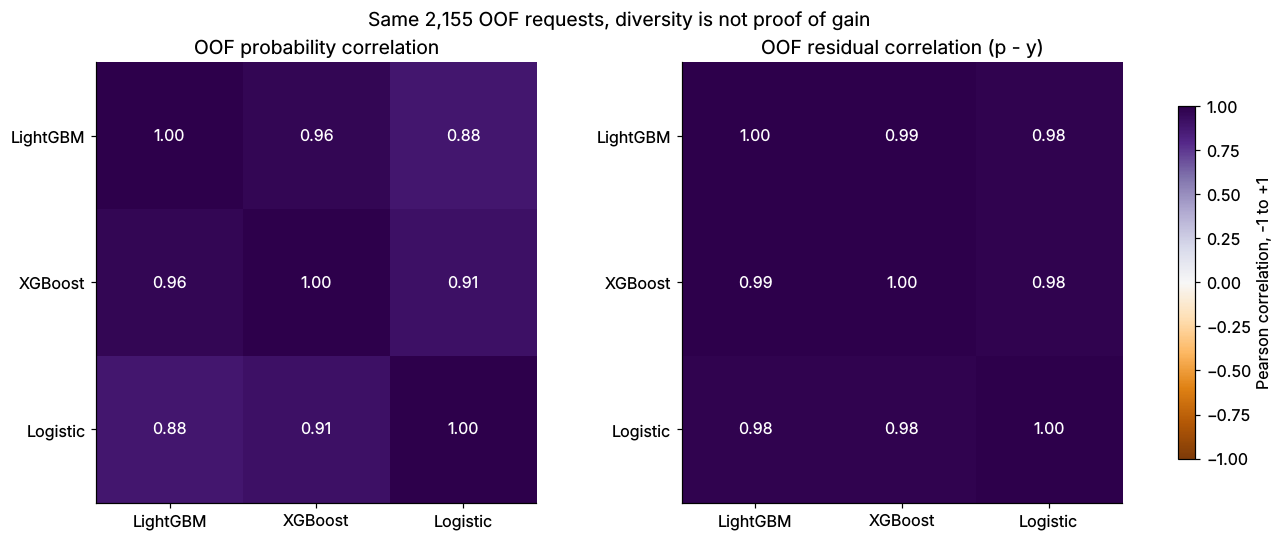

In [17]:
corr_p = pd.read_csv("artifacts/day5_probability_correlation.csv", index_col=0)
corr_r = pd.read_csv("artifacts/day5_residual_correlation.csv", index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, table, title in [(axes[0], corr_p, "OOF probability correlation"), (axes[1], corr_r, "OOF residual correlation (p - y)")]:
    im = ax.imshow(table, vmin=-1, vmax=1, cmap="PuOr"); ax.grid(False)
    ax.set_xticks(range(3), table.columns); ax.set_yticks(range(3), table.index); ax.set_title(title)
    for r in range(3):
        for c in range(3):
            v = table.iloc[r, c]; ax.text(c, r, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > .6 else "#222")
fig.colorbar(im, ax=axes, shrink=.8, label="Pearson correlation, -1 to +1")
fig.suptitle("Same 2,155 OOF requests, diversity is not proof of gain")
plt.show()

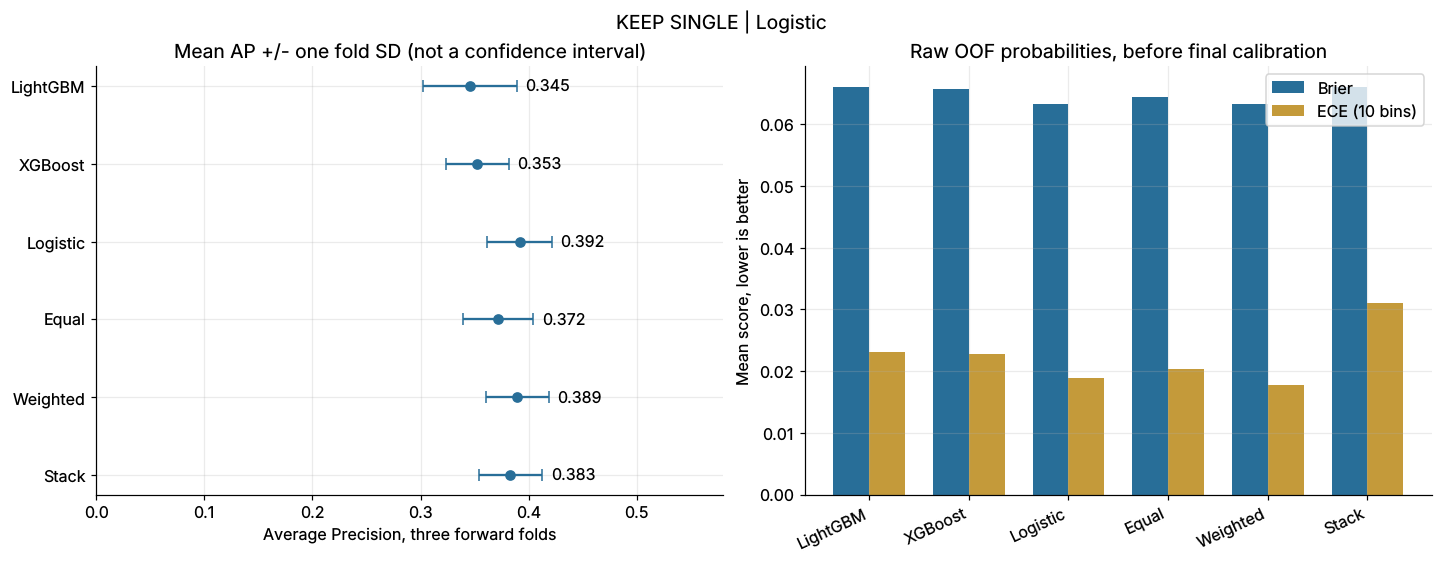

,mean_ap,fold_sd,mean_brier,mean_ece,lift_vs_single,passes_gate
candidate,,,,,,
LightGBM,0.3455,0.0435,0.0661,0.0231,-0.0462,False
XGBoost,0.3526,0.0290,0.0657,0.0228,-0.0390,False
Logistic,0.3917,0.0298,0.0633,0.0188,0.0000,False
Equal,0.3717,0.0326,0.0643,0.0204,-0.0200,False
Weighted,0.3894,0.0291,0.0633,0.0177,-0.0022,False
Stack,0.3831,0.0295,0.0660,0.0311,-0.0085,False


In [18]:
cmp5 = pd.read_csv("artifacts/ensemble_comparison.csv")
gate = read_json("artifacts/day5_ensemble_gate.json")
fig, (ax_ap, ax_cal) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for i, r in cmp5.iterrows():
    ax_ap.errorbar(r.mean_ap, i, xerr=r.fold_sd, fmt="o", color=BLUE, capsize=4)
    ax_ap.text(r.mean_ap + r.fold_sd + .008, i, f"{r.mean_ap:.3f}", va="center")
ax_ap.set_yticks(range(len(cmp5)), cmp5.candidate); ax_ap.invert_yaxis(); ax_ap.set_xlim(0, .58)
ax_ap.set(title="Mean AP +/- one fold SD (not a confidence interval)", xlabel="Average Precision, three forward folds")
x = np.arange(len(cmp5))
ax_cal.bar(x - .18, cmp5.mean_brier, .36, color=BLUE, label="Brier"); ax_cal.bar(x + .18, cmp5.mean_ece, .36, color=GOLD, label="ECE (10 bins)")
ax_cal.set_xticks(x, cmp5.candidate, rotation=25, ha="right"); ax_cal.legend()
ax_cal.set(title="Raw OOF probabilities, before final calibration", ylabel="Mean score, lower is better")
fig.suptitle(f"{gate['decision']} | {gate['chosen']}")
plt.show()
display(cmp5.round(4).set_index("candidate"))

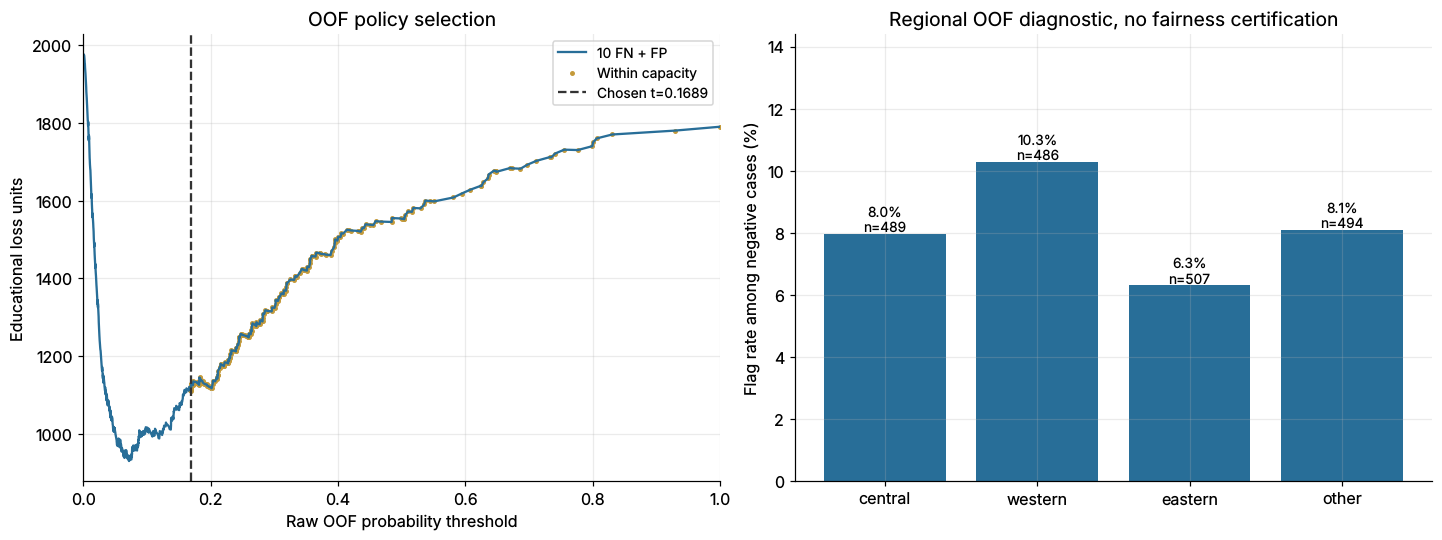

Highest-to-lowest regional flag rate gap: 3.98 percentage points (descriptive)


In [19]:
policy = read_json("artifacts/final_policy.json")
sweep5 = pd.read_csv("artifacts/day5_threshold_sweep.csv")
reg5 = pd.read_csv("artifacts/day5_region_audit.csv")
raw_t5 = policy["raw_oof_threshold"]
fig, (ax_loss, ax_reg) = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
ax_loss.plot(sweep5.threshold, sweep5.loss_units, color=BLUE, label="10 FN + FP")
ok = sweep5[sweep5.capacity_feasible]
ax_loss.scatter(ok.threshold, ok.loss_units, s=5, color=GOLD, label="Within capacity")
ax_loss.axvline(raw_t5, color="#333", ls="--", label=f"Chosen t={raw_t5:.4f}")
ax_loss.set(xlim=(0, 1), xlabel="Raw OOF probability threshold", ylabel="Educational loss units", title="OOF policy selection"); ax_loss.legend(fontsize=9)
ax_reg.bar(reg5.region, reg5.false_positive_rate * 100, color=BLUE)
for i, r in reg5.iterrows():
    ax_reg.text(i, r.false_positive_rate * 100, f"{r.false_positive_rate:.1%}\nn={r.negatives}", ha="center", va="bottom", fontsize=9)
ax_reg.set(title="Regional OOF diagnostic, no fairness certification", ylabel="Flag rate among negative cases (%)", ylim=(0, reg5.false_positive_rate.max() * 100 * 1.4))
plt.show()
gap = (reg5.false_positive_rate.max() - reg5.false_positive_rate.min()) * 100
print(f"Highest-to-lowest regional flag rate gap: {gap:.2f} percentage points (descriptive)")

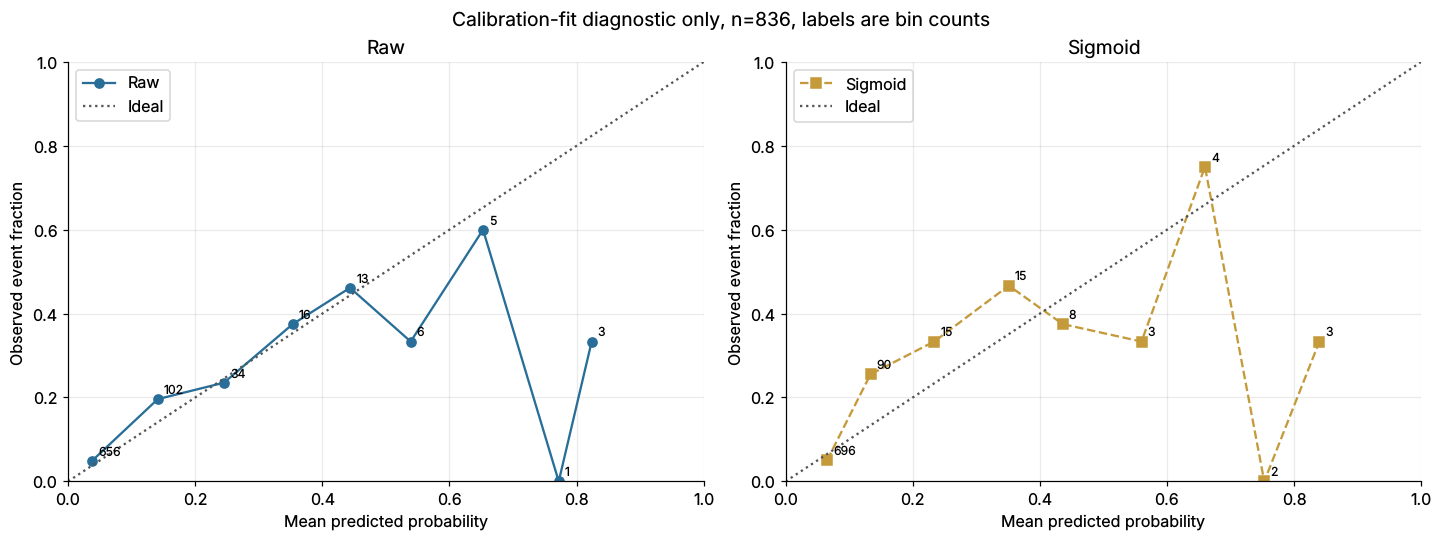

raw      Brier 0.0765 | ECE 0.0211 | AP 0.2878
sigmoid  Brier 0.0781 | ECE 0.0349 | AP 0.2878


In [20]:
fit_bins = pd.read_csv("artifacts/day5_calibration_fit_bins.csv")
diag = read_json("artifacts/final_metrics.json")["calibration_fit_diagnostics"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for ax, series, color, marker in [(axes[0], "Raw", BLUE, "o-"), (axes[1], "Sigmoid", GOLD, "s--")]:
    t = fit_bins[(fit_bins.series == series) & (fit_bins["count"] > 0)]
    ax.plot(t.mean_probability, t.observed_rate, marker, color=color, label=series)
    for _, r in t.iterrows():
        ax.annotate(str(int(r["count"])), (r.mean_probability, r.observed_rate), xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.plot([0, 1], [0, 1], ":", color="#555", label="Ideal")
    ax.set(xlim=(0, 1), ylim=(0, 1), title=series, xlabel="Mean predicted probability", ylabel="Observed event fraction"); ax.legend()
fig.suptitle(f"Calibration-fit diagnostic only, n={diag['raw_fit_diagnostic']['rows']}, labels are bin counts")
plt.show()
for k, label in [("raw_fit_diagnostic", "raw"), ("sigmoid_fit_diagnostic", "sigmoid")]:
    print(f"{label:8s} Brier {diag[k]['brier']:.4f} | ECE {diag[k]['ece']:.4f} | AP {diag[k]['average_precision']:.4f}")

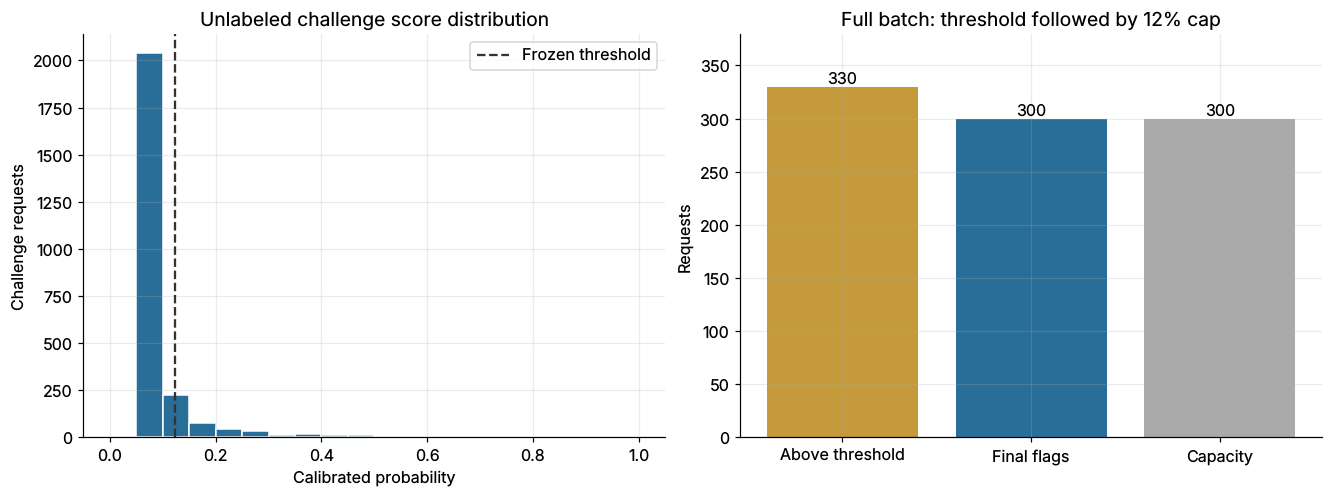

In [21]:
sub = pd.read_csv("submission/submission.csv")
audit = policy["batch_audit"]; thr = policy["calibrated_threshold"]
fig, (ax_hist, ax_bar) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
ax_hist.hist(sub.probability, bins=np.linspace(0, 1, 21), color=BLUE, edgecolor="white")
ax_hist.axvline(thr, color="#333", ls="--", label="Frozen threshold")
ax_hist.set(xlabel="Calibrated probability", ylabel="Challenge requests", title="Unlabeled challenge score distribution"); ax_hist.legend()
vals = [audit["threshold_eligible"], audit["flagged"], audit["capacity"]]
ax_bar.bar(["Above threshold", "Final flags", "Capacity"], vals, color=[GOLD, BLUE, "#aaaaaa"])
for i, n in enumerate(vals): ax_bar.text(i, n, str(n), ha="center", va="bottom")
ax_bar.set(ylabel="Requests", title="Full batch: threshold followed by 12% cap"); ax_bar.margins(y=.15)
plt.show()

**Reading Gate 5.** The three models make largely the same mistakes (residual correlation 0.98 to 0.99), so combining them has little room to help. Logistic Regression had the highest mean AP (0.392) and was among the best on Brier and ECE. No ensemble beat it by more than its fold standard deviation (0.030), so the decision is **KEEP SINGLE**. The final policy is the lowest-loss threshold within the 12% capacity ceiling. The sigmoid mapping did not improve the calibration-fit diagnostic on the reserved period (Brier 0.0765 to 0.0781, ECE 0.0211 to 0.0349). That diagnostic is scored on the same rows used to fit the mapping, so it is not an independent test.

## Part 8: Final result

The final cells print the decision and check that the submission file is consistent with the frozen policy.

In [22]:
gate = read_json("artifacts/day5_ensemble_gate.json")
run5 = read_json("artifacts/day5_run.json")
best = cmp5.set_index("candidate").loc[gate["chosen"]]
result = pd.DataFrame({
    "Item": ["Final decision", "Final model", "Mean AP across three forward folds", "Fold SD of AP (gate reference)",
             "Raw OOF threshold", "Calibrated (transported) threshold", "Loss function", "Capacity ceiling",
             "Challenge requests scored", "Above the threshold", "Final review flags (after cap)", "Removed by the 12% cap"],
    "Result": [gate["decision"], gate["chosen"], f"{best.mean_ap:.4f}", f"{gate['fold_sd_reference']:.4f}",
               f"{policy['raw_oof_threshold']:.4f}", f"{policy['calibrated_threshold']:.4f}",
               f"{policy['cost_policy']['false_negative_cost']:g} x FN + {policy['cost_policy']['false_positive_cost']:g} x FP (educational units)",
               f"{policy['cost_policy']['max_flag_fraction']:.0%} of the batch",
               f"{audit['rows']:,}", audit["threshold_eligible"], audit["flagged"], audit["removed_by_cap"]]})
display(result.set_index("Item"))

,Result
Item,
Final decision,KEEP SINGLE
Final model,Logistic
Mean AP across three forward folds,0.3917
Fold SD of AP (gate reference),0.0298
Raw OOF threshold,0.1689
Calibrated (transported) threshold,0.1223
Loss function,10 x FN + 1 x FP (educational units)
Capacity ceiling,12% of the batch
Challenge requests scored,"2,500"


In [23]:
# Integrity checks on the exported submission (read-only; nothing is recomputed or edited)
expected_ids = set(challenge.application_id)
checks = {
    "2,500 rows": len(sub) == 2500,
    "every challenge request appears exactly once": sub.application_id.is_unique and set(sub.application_id) == expected_ids,
    "probabilities are within 0 to 1": bool(sub.probability.between(0, 1).all()),
    "decisions are 0 or 1": set(sub.decision.unique()) <= {0, 1},
    f"flags within the {audit['capacity']}-request capacity": int(sub.decision.sum()) <= audit["capacity"],
    "flag count matches the frozen batch audit": int(sub.decision.sum()) == audit["flagged"],
    "every flagged request is at or above the frozen threshold": bool((sub.loc[sub.decision == 1, "probability"] >= thr).all()),
    "no unflagged request outranks a flagged one": bool(sub.loc[sub.decision == 0, "probability"].max() <= sub.loc[sub.decision == 1, "probability"].min() + 1e-12),
    "run record reports a live, technically ready run": run5["technical_status"] == "TECHNICAL_READY" and run5["source"] == "LIVE",
    "no challenge labels were used": run5["challenge_labels_used"] is False,
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "A submission check failed"
print("\nAll submission checks passed.")

PASS  2,500 rows
PASS  every challenge request appears exactly once
PASS  probabilities are within 0 to 1
PASS  decisions are 0 or 1
PASS  flags within the 300-request capacity
PASS  flag count matches the frozen batch audit
PASS  every flagged request is at or above the frozen threshold
PASS  no unflagged request outranks a flagged one
PASS  run record reports a live, technically ready run
PASS  no challenge labels were used

All submission checks passed.


### Final result summary

- **Decision: KEEP SINGLE.** Logistic Regression is the final model. It had the highest mean AP across the three forward folds (0.392). The weighted average scored 0.389, stacking 0.383 and the equal average 0.372, and none passed the worth-it gate, so the added complexity was not justified.
- **Policy.** The threshold minimises the educational loss (10 x false negatives + 1 x false positives) subject to a 12% review capacity in every period. The raw OOF threshold of 0.1689 is transported to 0.1223 on the calibrated scale.
- **Challenge predictions.** Of 2,500 requests, 330 exceeded the threshold. The 12% cap (300) was applied once to the whole batch, leaving 300 simulated review flags and removing 30. The file passes all consistency checks above.
- **Calibration.** One sigmoid mapping was learned on the reserved July to September 2024 period. On those same rows it did not improve Brier or ECE, so that result is reported as a fit diagnostic and not as independent performance.
- **Evidence.** The model, policy, metrics, predictions and reports are in `artifacts/`, `submission/` and `reports/`. The model card is `reports/MODEL_CARD.md`.

## Part 9: Interpretation and limitations

- The data are synthetic and do not represent real people or regions. The model is for training use only.
- A review flag is a simulated signal. A zero is not a safety guarantee or a financing approval.
- Out-of-fold results are used for development and selection. They are not an untouched final test, and three overlapping forward periods are not a significance test.
- The calibration figures are diagnostics on the rows used to fit the calibrator, not independent performance.
- Transporting a threshold from out-of-fold models to a refitted model can change the flag volume, which is why the capacity cap is applied once to the whole batch.
- Loss units are fictional teaching units, not riyals, and review cost is not included.
- No challenge labels are available, so no challenge performance is claimed.
- The regional diagnostic is descriptive and is not a fairness certification.
- The Gate 4 explanations describe the Gate 4 LightGBM model and are not automatically attributed to the final Logistic model.

**To reproduce the saved predictions** without refitting, run `python scripts/replay_final.py`. To rebuild everything from the data, run `python scripts/rebuild_final.py`. See `README.md` for the full repository map.